# Experimento multimodal: imágenes RGB + espectros STARLIGHT + poblaciones estelares

Experimento reproducible de clasificación binaria `temprana = 0.0` frente a `tardia = 1.0` mediante fusión por concatenación de tres ramas: un encoder visual (ResNet-18), un encoder espectral 1D y un MLP sobre las poblaciones estelares de STARLIGHT.

La cohorte, los splits y las transformaciones provienen exclusivamente de `src.dataloader.multimodal`. Se usa `fov_0` para imágenes, `spectra_cache_starlight` (espectro modelado, malla 3600–8900 Å) para espectros y `poblaciones_estelares` (`[2, 45]` aplanada a 90 valores, luz y masa renormalizadas) para poblaciones.

**Advertencia metodológica (guía 11.4 y 22.6):** el espectro modelado y las poblaciones derivan del mismo ajuste STARLIGHT, así que no son entradas independientes, y las poblaciones correlacionan con la morfología por asociación astrofísica. Reportar este experimento como de contexto físico y compararlo con las ablaciones (imagen sola, espectro solo, poblaciones solas, pares).

In [1]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, f1_score
from torch import nn
from tqdm.auto import tqdm


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

/home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Proyecto: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Dispositivo: cuda


## Configuración e invariantes

- El split `data/processed/splits_seed42_obj-label_FoV.csv` es fijo: no se regenera dentro del experimento.
- Se activa exactamente la cohorte con imágenes `fov_0`, espectros listos en `spectra_cache_starlight` y poblaciones disponibles para todos los IDs.
- La normalización de imagen es `none` porque el ResNet se inicializa aleatoriamente; no se descargan pesos ImageNet.
- La selección de checkpoints usa solo validación; `test` se consulta una única vez para el modelo seleccionado.
- Se usa una salida logit por galaxia y `BCEWithLogitsLoss`.

In [2]:
CONFIG: dict[str, Any] = {
    "experiment_name": "multimodal_imagenes_espectros_poblaciones_starlight_concat",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label_FoV.csv",
        "modalities": ["image", "spectrum", "populations"],
        "image": {
            "fov_column": "fov_0",
            "size": 256,
            "normalization": "none",
        },
        "spectrum": {
            "cache_dir": "data/processed/spectra/spectra_cache_starlight",
        },
        "populations": {
            "dir": "data/processed/starlight/poblaciones_estelares",
            "channels": ["luz_pct", "masa_actual_pct"],
            "renormalize": True,
            "flatten": True,
        },
    },
    "model": {
        "image_embedding_dim": 128,
        "spectrum_embedding_dim": 128,
        "population_embedding_dim": 64,
        "classifier_hidden_dim": 128,
        "dropout": 0.3,
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 50,
        "learning_rate": 1e-4,
        "weight_decay": 1e-4,
        "early_stopping_patience": 8,
    },
    "selection_metric": "roc_auc",
}

RUN_DIR = ROOT / "models" / "experiments" / CONFIG["experiment_name"]
CHECKPOINT_PATH = RUN_DIR / "best_model.pt"
RESULTS_PATH = RUN_DIR / "results.json"
CONFIG_PATH = RUN_DIR / "config.json"

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
loaders = {"train": train_loader, "validation": validation_loader, "test": test_loader}

for split_name, loader in loaders.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:16s} {tuple(value.shape)} {value.dtype}")
    else:
        print(f"{key:16s} {type(value).__name__}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,) torch.float32
image            (32, 3, 256, 256) torch.float32
populations      (32, 90) torch.float32
spectrum         (32, 1, 4096) torch.float32
spectrum_mask    (32, 4096) torch.bool


## Modelo: fusión por concatenación de tres ramas

La línea base usa un ResNet-18 inicializado aleatoriamente para el RGB, una CNN 1D con pooling enmascarado para el espectro modelado de STARLIGHT y un MLP para las 90 fracciones de población. Los tres embeddings se concatenan antes del clasificador, sin metadatos.

In [4]:
import torch.nn.functional as F
from torchvision.models import resnet18


class ImageEncoder(nn.Module):
    def __init__(self, embedding_dim: int, dropout: float) -> None:
        super().__init__()
        backbone = resnet18(weights=None)
        self.features = nn.Sequential(*list(backbone.children())[:-1])
        self.projection = nn.Sequential(
            nn.Flatten(),
            nn.Linear(backbone.fc.in_features, embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        return self.projection(self.features(image))


class SpectrumEncoder(nn.Module):
    def __init__(self, input_channels: int, embedding_dim: int, dropout: float) -> None:
        super().__init__()
        channels = (input_channels, 32, 64, 128)
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv1d(in_channels, out_channels, kernel_size=5, stride=2, padding=2),
                    nn.GELU(),
                )
                for in_channels, out_channels in zip(channels[:-1], channels[1:])
            ]
        )
        self.projection = nn.Sequential(
            nn.Linear(channels[-1], embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    @staticmethod
    def _downsample_mask(mask: torch.Tensor) -> torch.Tensor:
        return F.max_pool1d(mask.float().unsqueeze(1), kernel_size=5, stride=2, padding=2).squeeze(1).bool()

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        if spectrum.ndim != 3 or mask.shape != spectrum.shape[:1] + spectrum.shape[2:]:
            raise ValueError("Se esperaba spectrum=[B, C, L] y spectrum_mask=[B, L].")
        mask = mask.bool()
        for block in self.blocks:
            spectrum = block(spectrum)
            mask = self._downsample_mask(mask)
            spectrum = spectrum * mask.unsqueeze(1)
        weights = mask.unsqueeze(1).to(spectrum.dtype)
        pooled = (spectrum * weights).sum(dim=-1) / weights.sum(dim=-1).clamp_min(1.0)
        return self.projection(pooled)


class PopulationEncoder(nn.Module):
    def __init__(self, input_dim: int, embedding_dim: int, dropout: float) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, embedding_dim),
            nn.ReLU(inplace=True),
        )

    def forward(self, populations: torch.Tensor) -> torch.Tensor:
        return self.network(populations)


class ImageSpectrumPopulationFusionClassifier(nn.Module):
    def __init__(
        self,
        spectrum_channels: int,
        population_dim: int,
        image_embedding_dim: int,
        spectrum_embedding_dim: int,
        population_embedding_dim: int,
        classifier_hidden_dim: int,
        dropout: float,
    ) -> None:
        super().__init__()
        self.image_encoder = ImageEncoder(image_embedding_dim, dropout)
        self.spectrum_encoder = SpectrumEncoder(spectrum_channels, spectrum_embedding_dim, dropout)
        self.population_encoder = PopulationEncoder(population_dim, population_embedding_dim, dropout)
        fused_dim = image_embedding_dim + spectrum_embedding_dim + population_embedding_dim
        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, classifier_hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(classifier_hidden_dim, 1),
        )

    def forward(self, batch: Mapping[str, Any]) -> torch.Tensor:
        embeddings = (
            self.image_encoder(batch["image"]),
            self.spectrum_encoder(batch["spectrum"], batch["spectrum_mask"]),
            self.population_encoder(batch["populations"]),
        )
        return self.classifier(torch.cat(embeddings, dim=1)).squeeze(1)


def build_model(config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    model_config = config["model"]
    return ImageSpectrumPopulationFusionClassifier(
        spectrum_channels=batch["spectrum"].shape[1],
        population_dim=batch["populations"].shape[1],
        image_embedding_dim=int(model_config["image_embedding_dim"]),
        spectrum_embedding_dim=int(model_config["spectrum_embedding_dim"]),
        population_embedding_dim=int(model_config["population_embedding_dim"]),
        classifier_hidden_dim=int(model_config["classifier_hidden_dim"]),
        dropout=float(model_config["dropout"]),
    )


model = build_model(CONFIG, sample_batch).to(DEVICE)
with torch.no_grad():
    batch_on_device = {
        key: value.to(DEVICE, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in sample_batch.items()
    }
    logits = model(batch_on_device)
if logits.shape != sample_batch["label"].shape:
    raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(sample_batch['label'].shape)}.")
assert torch.isfinite(logits).all()
print(model)
print(f"Forward de prueba: {tuple(logits.shape)}")

ImageSpectrumPopulationFusionClassifier(
  (image_encoder): ImageEncoder(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (4): Sequential(
        (0): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu): ReLU(inplace=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (1): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False

In [5]:
def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {
        key: value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in batch.items()
    }


def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    expected_shape = batch["label"].shape
    if logits.shape != expected_shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(expected_shape)}.")
    return logits


def train_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    epoch: int,
    total_epochs: int,
) -> float:
    model.train()
    total_loss = 0.0
    progress = tqdm(
        loader,
        desc=f"Epoch {epoch:02d}/{total_epochs}",
        unit="batch",
        leave=False,
    )
    for batch in progress:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        total_loss += criterion(logits, batch["label"]).item() * batch["label"].numel()
        probabilities = torch.sigmoid(logits)
        all_true.append(batch["label"].cpu().numpy())
        all_pred.append((probabilities >= 0.5).to(torch.int64).cpu().numpy())
        all_proba.append(probabilities.cpu().numpy())
    return (
        total_loss / len(loader.dataset),
        np.concatenate(all_true),
        np.concatenate(all_pred),
        np.concatenate(all_proba),
    )

In [6]:
def fit(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    validation_loader: torch.utils.data.DataLoader,
    config: Mapping[str, Any],
    device: torch.device,
    checkpoint_path: Path,
) -> pd.DataFrame:
    training_config = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=training_config["learning_rate"],
        weight_decay=training_config["weight_decay"],
    )
    history: list[dict[str, float]] = []
    best_score = float("-inf")
    best_state: dict[str, torch.Tensor] | None = None
    epochs_without_improvement = 0

    for epoch in range(1, training_config["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(model, 
                                train_loader, 
                                optimizer, criterion, device, epoch, training_config["epochs"])
        validation_loss, y_true, y_pred, y_proba = evaluate_epoch(
            model, validation_loader, criterion, device
        )
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": float(metrics["accuracy"]),
                "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
                "validation_f1": f1_score(y_true, y_pred, zero_division=0),
                "validation_roc_auc": float(metrics["roc_auc"]),
                "seconds": time.perf_counter() - started_at,
            }
        )
        print(
            f"[{epoch:02d}/{training_config['epochs']}] "
            f"train_loss={train_loss:.4f} val_loss={validation_loss:.4f} "
            f"val_auc={metrics['roc_auc']:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= training_config["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "config": dict(config)}, checkpoint_path)
    return pd.DataFrame(history)


# Para entrenar después de implementar build_model:
model = build_model(CONFIG, sample_batch).to(DEVICE)
history = fit(model, train_loader, validation_loader, CONFIG, DEVICE, CHECKPOINT_PATH)

[01/50] train_loss=0.4122 val_loss=0.3782 val_auc=0.9103


[02/50] train_loss=0.3403 val_loss=0.3184 val_auc=0.9373


[03/50] train_loss=0.3068 val_loss=0.2736 val_auc=0.9519


[04/50] train_loss=0.2948 val_loss=0.2855 val_auc=0.9493


[05/50] train_loss=0.2746 val_loss=0.3196 val_auc=0.9551


[06/50] train_loss=0.2652 val_loss=0.2789 val_auc=0.9552


... (17 outputs left out)

[24/50] train_loss=0.1750 val_loss=0.2882 val_auc=0.9537


[25/50] train_loss=0.1749 val_loss=0.3048 val_auc=0.9600


[26/50] train_loss=0.1724 val_loss=0.2787 val_auc=0.9631


[27/50] train_loss=0.1693 val_loss=0.2925 val_auc=0.9591
Early stopping por validación.


## Evaluación final y persistencia

Ejecute esta sección solo después de decidir la arquitectura e hiperparámetros usando validación. El split de `test` no participa en selección, calibración ni early stopping.

test_loss=0.2440  test_accuracy=0.8895  test_auc=0.9650
              precision    recall  f1-score      support
0.0            0.833631  0.882576  0.857406   528.000000
1.0            0.926540  0.893714  0.909831   875.000000
accuracy       0.889522  0.889522  0.889522     0.889522
macro avg      0.880086  0.888145  0.883619  1403.000000
weighted avg   0.891575  0.889522  0.890102  1403.000000


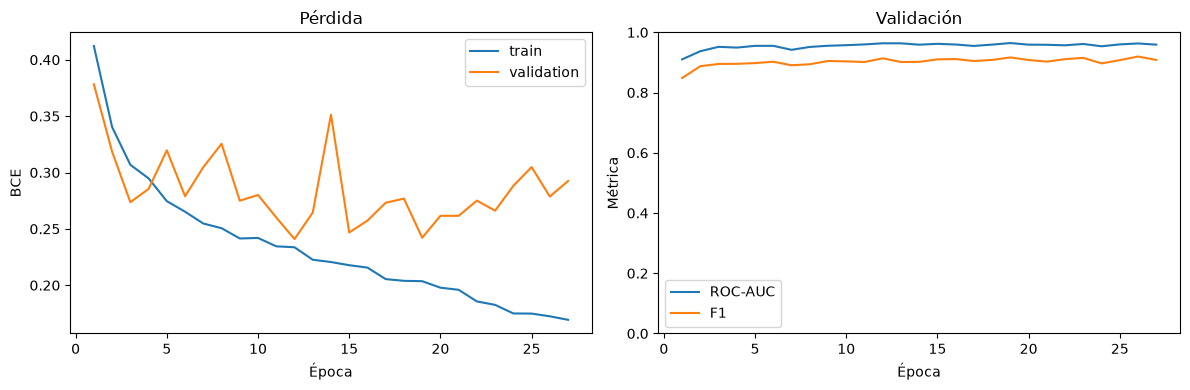

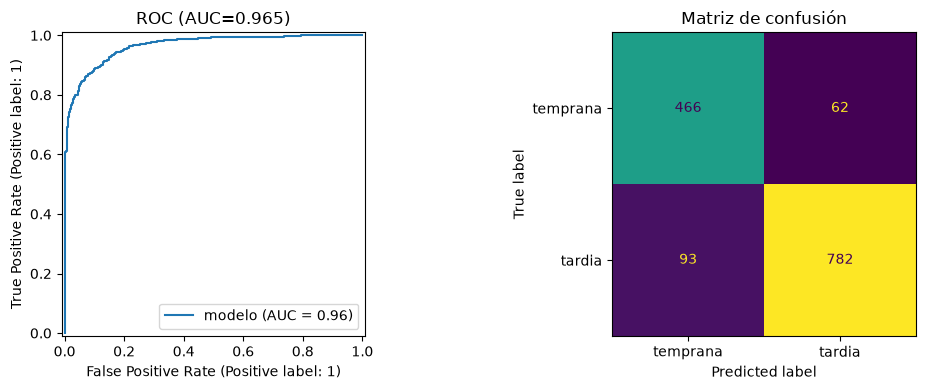

In [7]:
def plot_history(history: pd.DataFrame) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
    axes[0].set(title="Pérdida", xlabel="Época", ylabel="BCE")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["validation_roc_auc"], label="ROC-AUC")
    axes[1].plot(history["epoch"], history["validation_f1"], label="F1")
    axes[1].set(title="Validación", xlabel="Época", ylabel="Métrica", ylim=(0, 1))
    axes[1].legend()
    figure.tight_layout()


def plot_binary_evaluation(y_true: np.ndarray, y_proba: np.ndarray, metrics: Mapping[str, Any]) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0], name="modelo")
    axes[0].set_title(f"ROC (AUC={metrics['roc_auc']:.3f})")
    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=["temprana", "tardia"],
    ).plot(ax=axes[1], colorbar=False)
    axes[1].set_title("Matriz de confusión")
    figure.tight_layout()


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(item) for item in value]
    return value


def save_run_artifacts(
    config: Mapping[str, Any], history: pd.DataFrame, test_metrics: Mapping[str, Any]
) -> None:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    with CONFIG_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(config), file, indent=2)
    history.to_csv(RUN_DIR / "history.csv", index=False)
    with RESULTS_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(test_metrics), file, indent=2)


# Después de seleccionar el experimento con validación:
criterion = nn.BCEWithLogitsLoss()
test_loss, y_test, y_test_pred, y_test_proba = evaluate_epoch(model, test_loader, criterion, DEVICE)
test_metrics = evaluate_binary_classifier(y_test, y_test_pred, y_test_proba)
print(f"test_loss={test_loss:.4f}  test_accuracy={test_metrics['accuracy']:.4f}  test_auc={test_metrics['roc_auc']:.4f}")
print(pd.DataFrame(test_metrics["report"]).T)
plot_history(history)
plot_binary_evaluation(y_test, y_test_proba, test_metrics)
save_run_artifacts(CONFIG, history, {"test_loss": test_loss, **test_metrics})

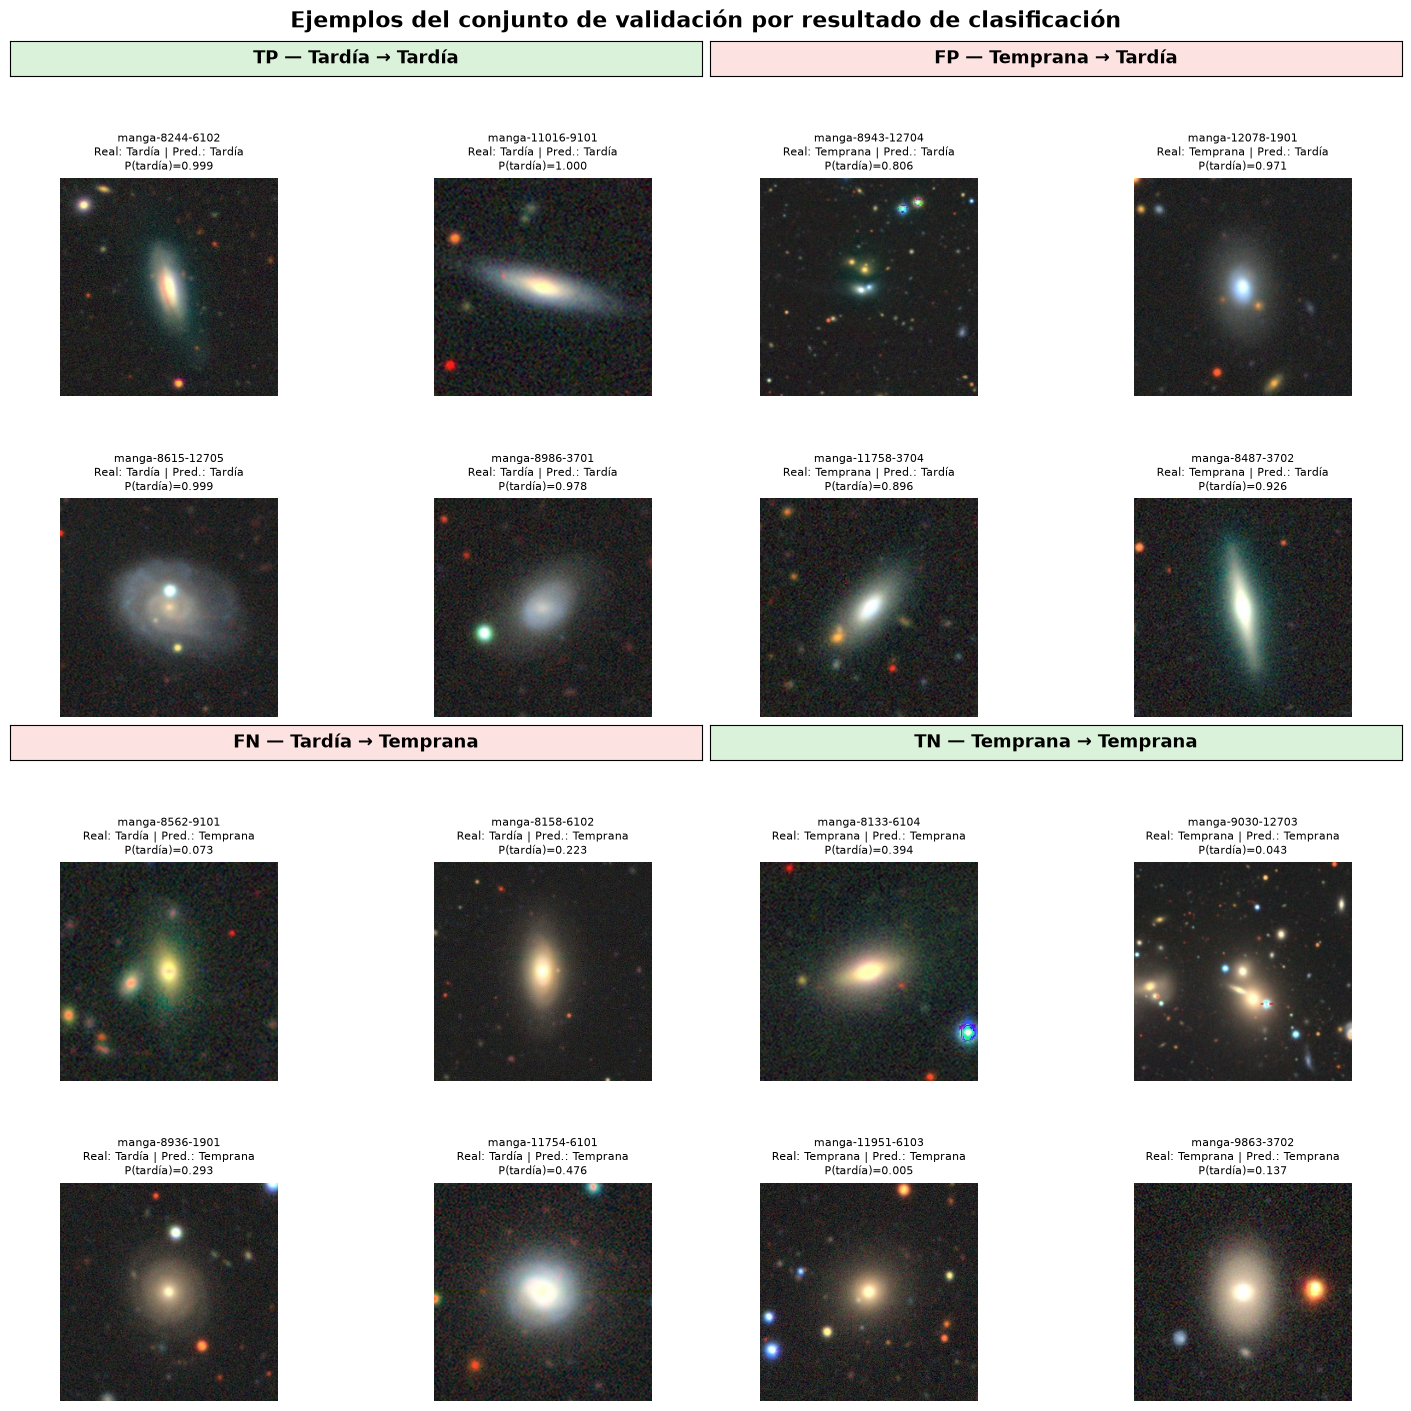

In [8]:
# Evaluación visual del modelo:
# matriz de confusión + 4 ejemplos TN, TP, FP y FN del split de validación.
#
# Convención del proyecto:
#   0 = temprana
#   1 = tardía
#
# Por tanto:
#   TN: temprana -> temprana
#   TP: tardía   -> tardía
#   FP: temprana -> tardía
#   FN: tardía   -> temprana

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix

CLASS_NAMES = {0: "Temprana", 1: "Tardía"}
THRESHOLD = 0.5
N_EXAMPLES_PER_GROUP = 4
RNG = np.random.default_rng(42)

model.eval()

all_ids = []
all_images = []
all_targets = []
all_probabilities = []

with torch.no_grad():
    for batch in validation_loader:
        batch_on_device = {
            key: value.to(DEVICE, non_blocking=True)
            if isinstance(value, torch.Tensor)
            else value
            for key, value in batch.items()
        }

        logits = model(batch_on_device).squeeze(-1)
        probabilities = torch.sigmoid(logits)

        all_ids.extend(batch["id"])
        all_images.append(batch["image"].cpu())
        all_targets.append(batch["label"].to(torch.int64).cpu())
        all_probabilities.append(probabilities.cpu())

images = torch.cat(all_images).numpy()
y_true = torch.cat(all_targets).numpy()
y_proba = torch.cat(all_probabilities).numpy()
y_pred = (y_proba >= THRESHOLD).astype(np.int64)

# --- Matriz de confusión ---
matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

# --- Índices por resultado de clasificación ---
groups = {
    "TN — Temprana → Temprana": np.flatnonzero(
        (y_true == 0) & (y_pred == 0)
    ),
    "TP — Tardía → Tardía": np.flatnonzero(
        (y_true == 1) & (y_pred == 1)
    ),
    "FP — Temprana → Tardía": np.flatnonzero(
        (y_true == 0) & (y_pred == 1)
    ),
    "FN — Tardía → Temprana": np.flatnonzero(
        (y_true == 1) & (y_pred == 0)
    ),
}

# Revertir la normalización ImageNet aplicada por el transform de imágenes.
def image_for_display_imagenet(image: np.ndarray) -> np.ndarray:
    image = np.moveaxis(image, 0, -1)  # C, H, W -> H, W, C

    imagenet_mean = np.array([0.485, 0.456, 0.406])
    imagenet_std = np.array([0.229, 0.224, 0.225])

    image = image * imagenet_std + imagenet_mean
    return np.clip(image, 0, 1)

def image_for_display(image: np.ndarray) -> np.ndarray:
    """Convierte una imagen CxHxW en HxWxC para matplotlib."""
    image = np.moveaxis(image, 0, -1)  # C, H, W -> H, W, C
    return np.clip(image, 0, 1)


# --- Panel por cuadrantes: cuatro ejemplos en cada categoría ---
#
# Organización visual solicitada:
#     TP | FP
#    ---+---
#     FN | TN

quadrants = [
    (
        "TP — Tardía → Tardía",
        np.flatnonzero((y_true == 1) & (y_pred == 1)),
        "#d9f2d9",
    ),
    (
        "FP — Temprana → Tardía",
        np.flatnonzero((y_true == 0) & (y_pred == 1)),
        "#fde2e2",
    ),
    (
        "FN — Tardía → Temprana",
        np.flatnonzero((y_true == 1) & (y_pred == 0)),
        "#fde2e2",
    ),
    (
        "TN — Temprana → Temprana",
        np.flatnonzero((y_true == 0) & (y_pred == 0)),
        "#d9f2d9",
    ),
]

fig = plt.figure(figsize=(14, 14), constrained_layout=True)
outer_grid = fig.add_gridspec(nrows=2, ncols=2, wspace=0.08, hspace=0.12)

for quadrant_index, (title, indices, background_color) in enumerate(quadrants):
    row, column = divmod(quadrant_index, 2)
    quadrant_grid = outer_grid[row, column].subgridspec(
        nrows=3,
        ncols=2,
        height_ratios=[0.16, 1, 1],
        hspace=0.12,
        wspace=0.08,
    )

    # Título que ocupa el ancho completo del cuadrante.
    title_ax = fig.add_subplot(quadrant_grid[0, :])
    title_ax.set_facecolor(background_color)
    title_ax.text(
        0.5,
        0.5,
        title,
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
    )
    title_ax.set_xticks([])
    title_ax.set_yticks([])

    if len(indices) == 0:
        selected_indices = np.array([], dtype=int)
        print(f"No hay ejemplos para: {title}")
    else:
        selected_indices = RNG.choice(
            indices,
            size=min(N_EXAMPLES_PER_GROUP, len(indices)),
            replace=False,
        )

    # Cuadrícula interior 2x2: cuatro ejemplos del tipo indicado.
    for example_position in range(N_EXAMPLES_PER_GROUP):
        image_row, image_column = divmod(example_position, 2)
        ax = fig.add_subplot(
            quadrant_grid[image_row + 1, image_column]
        )

        if example_position >= len(selected_indices):
            ax.axis("off")
            continue

        index = selected_indices[example_position]

        ax.imshow(image_for_display(images[index]))
        ax.set_title(
            f"{all_ids[index]}\n"
            f"Real: {CLASS_NAMES[y_true[index]]} | "
            f"Pred.: {CLASS_NAMES[y_pred[index]]}\n"
            f"P(tardía)={y_proba[index]:.3f}",
            fontsize=8,
        )
        ax.axis("off")

fig.suptitle(
    "Ejemplos del conjunto de validación por resultado de clasificación",
    fontsize=16,
    fontweight="bold",
)
plt.show()

In [9]:
# Guarda
RUN_DIR.mkdir(parents=True, exist_ok=True)

experiment_data = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
    },
    "config": to_jsonable(CONFIG),
    "device": str(DEVICE),
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "history": history.to_dict(orient="records"),
    "test_metrics": to_jsonable(
        {"test_loss": test_loss, **test_metrics}
    ),
}

checkpoint_path = RUN_DIR / "experiment_checkpoint.pt"
torch.save(experiment_data, checkpoint_path)

with (RUN_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(CONFIG), file, indent=2)

history.to_csv(RUN_DIR / "history.csv", index=False)

with (RUN_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        to_jsonable({"test_loss": test_loss, **test_metrics}),
        file,
        indent=2,
    )

print(f"Modelo y resultados guardados en: {RUN_DIR}")
print(f"Checkpoint: {checkpoint_path}")

Modelo y resultados guardados en: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/multimodal_imagenes_espectros_poblaciones_starlight_concat
Checkpoint: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/multimodal_imagenes_espectros_poblaciones_starlight_concat/experiment_checkpoint.pt


# Save predictions

In [6]:
from torch.utils.data import DataLoader
import pandas as pd
from tqdm import tqdm

# Cargar el mejor checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE).eval()

THRESHOLD = 0.5
INT_TO_LABEL = {0: "temprana", 1: "tardia"}


@torch.no_grad()
def predict_split(dataset, split_name: str) -> pd.DataFrame:
    # El loader de train usa shuffle=True; se reconstruye sin shuffle para predecir.
    loader = DataLoader(
        dataset,
        batch_size=CONFIG["training"]["batch_size"],
        shuffle=False,
        num_workers=CONFIG["training"]["num_workers"],
        pin_memory=CONFIG["training"]["pin_memory"],
    )
    rows = []
    for batch in tqdm(loader, desc=f"Predict {split_name}", unit="batch", leave=False):
        ids = list(batch["id"])
        labels = batch["label"].to(torch.int64).numpy()
        logits = model(move_batch_to_device(batch, DEVICE))
        probas = torch.sigmoid(logits).cpu().numpy().astype(np.float64)
        rows.append(
            pd.DataFrame(
                {
                    "name": ids,
                    "split": split_name,
                    "y_true": labels,
                    "y_proba": probas,
                    "y_pred": (probas >= THRESHOLD).astype(np.int64),
                }
            )
        )
    return pd.concat(rows, ignore_index=True)


predictions = pd.concat(
    [
        predict_split(loader.dataset, split_name)
        for split_name, loader in loaders.items()
    ],
    ignore_index=True,
)
predictions["label"] = predictions["y_true"].map(INT_TO_LABEL)
predictions["pred_label"] = predictions["y_pred"].map(INT_TO_LABEL)
predictions["correct"] = predictions["y_true"] == predictions["y_pred"]
predictions = predictions[
    ["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]
]

PREDICTIONS_PATH = RUN_DIR / "predictions.csv"
predictions.to_csv(PREDICTIONS_PATH, index=False)
print(f"Guardado: {PREDICTIONS_PATH}  ({len(predictions)} filas)")
print(predictions.groupby("split")["correct"].mean().rename("accuracy"))
predictions.head()

Guardado: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/multimodal_imagenes_espectros_poblaciones_starlight_concat/predictions.csv  (9351 filas)
split
test          0.889522
train         0.922842
validation    0.897363
Name: accuracy, dtype: float64


,name,split,label,y_true,y_proba,y_pred,pred_label,correct
0,manga-10001-12701,train,tardia,1,0.998274,1,tardia,True
1,manga-10001-1902,train,temprana,0,0.064371,0,temprana,True
2,manga-10001-3702,train,temprana,0,0.034718,0,temprana,True
3,manga-10001-3703,train,tardia,1,0.992977,1,tardia,True
4,manga-10001-3704,train,temprana,0,0.023216,0,temprana,True
